# Exploratory Data Analysis — Pleural Effusion across three CXR datasets

**This analysis was heavily supported by Claude

| Dataset | Country | Role |
|---|---|---|
| **NIH ChestX-ray14** | USA | primary source |
| **CheXpert (Plus)** | USA | supplemental source |
| **VinBigData** | Vietnam | target (held-out test set always comes from here) |

The design holds architecture, image size, projection, training-set size and training-set
pleural-effusion prevalence constant across experiments. This notebook checks what the data
look like with respect to those constraints:

1. Unified per-image table built from the outputs of `download_data_scripts/`
2. File integrity (labels ↔ images)
3. Pleural effusion prevalence, and what it implies for fixed-size / fixed-prevalence training sets
4. Patient structure and train/test leakage
5. Label quality (VinBigData reader agreement, CheXpert uncertain labels)
6. Demographics and view position (AP vs PA)
7. Original acquisition resolution
8. Co-occurring findings
9. Pixel-level comparison: example images, intensity statistics, mean images, and a low-dimensional
   embedding of the four domains

*BIMCV PadChest was dropped: its downloaded images could not be matched to their labels (the `image_{k}` renaming did not follow the label-CSV row order).*

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

DATA_DIR = Path("data")
RNG = np.random.default_rng(42)
DATASETS = ["NIH", "CheXpert", "VinBigData"]
COLORS = dict(zip(DATASETS, ["#84aef0", "#f8df98", "#50a85c"]))

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Build a unified per-image table

Each download script saved a `*_TRAIN.csv` / `*_TEST.csv` split plus the raw metadata. A few
details matter for joining these back to image files:

- **NIH** images were renamed `image_{i:05d}.png` by their order in the zip,
  so the file for raw-metadata row *k* (0-based) is `image_{k+1:05d}.png`. This assumes the zip
  order matched the CSV order — §2b checks this.
- **CheXpert** labels come from three CheXbert label files (report / findings / impression);
  disputed images were removed and the label is positive if any source is positive.
- **VinBigData**'s raw annotation table has **one row per radiologist annotation**
  (3 readers × possibly several boxes); the split CSVs hold one row per image, labelled positive
  if any reader marked pleural effusion.

In [2]:
# NIH
nih_raw = pd.read_csv(DATA_DIR / "nih_labels.csv").drop(columns=["Unnamed: 11"], errors="ignore")
nih_raw["file"] = [f"image_{k + 1:05d}.png" for k in range(len(nih_raw))]
nih_split = pd.concat([
    pd.read_csv(DATA_DIR / "nih_labels_TRAIN.csv").assign(split="train"),
    pd.read_csv(DATA_DIR / "nih_labels_TEST.csv").assign(split="test"),
])
nih = nih_raw.merge(nih_split[["Image Index", "split", "label"]], on="Image Index", how="inner")
nih = pd.DataFrame({
    "dataset": "NIH",
    "image_id": nih["Image Index"],
    "path": "nih_images/" + nih["file"],
    "patient_id": nih["Patient ID"].astype(str),
    "split": nih["split"],
    "label": nih["label"].astype(bool),
    "sex": nih["Patient Gender"],
    "age": nih["Patient Age"].astype(float),
    "view": nih["View Position"],
    "orig_h": nih["Height]"],
    "orig_w": nih["OriginalImage[Width"],
    "findings": nih["Finding Labels"].str.split("|"),
})
nih.head(3)

,dataset,image_id,path,patient_id,split,label,sex,age,view,orig_h,orig_w,findings
0,NIH,00000001_000.png,nih_images/image_00001.png,1,train,False,M,58.0,PA,2749,2682,[Cardiomegaly]
1,NIH,00000001_001.png,nih_images/image_00002.png,1,train,False,M,58.0,PA,2729,2894,"[Cardiomegaly, Emphysema]"
2,NIH,00000001_002.png,nih_images/image_00003.png,1,train,True,M,58.0,PA,2048,2500,"[Cardiomegaly, Effusion]"


In [3]:
# CheXpert
# no CheXpert test split: all experiments are tested on VinBigData
chx_split = pd.read_csv(DATA_DIR / "chexpert_labels_TRAIN.csv").assign(split="train")


def load_chexpert(path, keep):
    rows = [json.loads(l) for l in path.read_text(encoding="utf-8-sig").splitlines() if l.strip()]
    df = pd.DataFrame(rows)
    df["filename"] = df["path_to_image"].apply(
        lambda x: Path(x.replace("/", "_").split("_", 1)[-1]).with_suffix(".png").name)
    return df[df["filename"].isin(keep)].drop_duplicates("filename").set_index("filename")


chx_report = load_chexpert(DATA_DIR / "chexpert_report_labels.json",
                           {p.name for p in (DATA_DIR / "chexpert_images").glob("*.png")})
CHX_CLASSES = [c for c in chx_report.columns if c not in ("path_to_image",)]

chx_meta = pd.read_csv(DATA_DIR / "chexpert_plus_meta.csv")
chx_meta["filename"] = chx_meta["path_to_image"].apply(
    lambda x: Path(x.replace("/", "_").split("_", 1)[-1]).with_suffix(".png").name)
chx_meta = chx_meta.drop_duplicates("filename").set_index("filename").reindex(chx_split["filename"])

chx = pd.DataFrame({
    "dataset": "CheXpert",
    "image_id": chx_split["filename"].values,
    "path": ("chexpert_images/" + chx_split["filename"]).values,
    "patient_id": chx_split["filename"].str.split("_").str[0].values,
    "split": chx_split["split"].values,
    "label": chx_split["label"].astype(bool).values,
    "sex": chx_meta["sex"].map({"Male": "M", "Female": "F"}).values,
    "age": chx_meta["age"].values,
    "view": chx_meta["ap_pa"].values,
    "orig_h": np.nan,
    "orig_w": np.nan,
})
chx["findings"] = chx["image_id"].map(
    lambda f: [c for c in CHX_CLASSES if f in chx_report.index and chx_report.at[f, c] == 1.0])
chx.head(3)

,dataset,image_id,path,patient_id,split,label,sex,age,view,orig_h,orig_w,findings
0,CheXpert,patient04528_study1_view1_frontal.png,chexpert_images/patient04528_study1_view1_fron...,patient04528,train,False,F,62.0,PA,NaN,NaN,"[Lung Opacity, Support Devices]"
1,CheXpert,patient02244_study2_view1_frontal.png,chexpert_images/patient02244_study2_view1_fron...,patient02244,train,True,F,62.0,PA,NaN,NaN,"[Atelectasis, Pleural Effusion, Support Devices]"
2,CheXpert,patient06050_study1_view1_frontal.png,chexpert_images/patient06050_study1_view1_fron...,patient06050,train,False,M,65.0,PA,NaN,NaN,[Fracture]


In [4]:
# VinBigData 
vb_rows = pd.read_csv(DATA_DIR / "vinbigdata_labels.csv")
vb_meta = pd.read_csv(DATA_DIR / "vinbigdata_meta.csv")
vb_split = pd.concat([
    pd.read_csv(DATA_DIR / "vinbigdata_labels_TRAIN.csv").assign(split="train"),
    pd.read_csv(DATA_DIR / "vinbigdata_labels_TEST.csv").assign(split="test"),
]).drop_duplicates("image_id")[["image_id", "split"]]

vb_rows["is_pe"] = vb_rows["class_name"].eq("Pleural effusion")

vb_votes = vb_rows.groupby(["image_id", "rad_id"])["is_pe"].any().groupby("image_id").sum().rename("pe_votes")
vb_find = vb_rows.groupby("image_id")["class_name"].apply(lambda s: sorted(set(s) - {"No finding"}))

vb = vb_split.merge(vb_votes, on="image_id").merge(vb_meta, on="image_id")
vb = pd.DataFrame({
    "dataset": "VinBigData",
    "image_id": vb["image_id"],
    "path": "vinbigdata_images/" + vb["image_id"] + ".png",
    "patient_id": vb["image_id"],   
    "split": vb["split"],
    "label": vb["pe_votes"] >= 1,   
    "pe_votes": vb["pe_votes"],
    "sex": np.nan,
    "age": np.nan,
    "view": "PA (per dataset docs)",
    "orig_h": vb["dim0"],
    "orig_w": vb["dim1"],
    "findings": vb["image_id"].map(vb_find),
})
vb.head(3)

,dataset,image_id,path,patient_id,split,label,pe_votes,sex,age,view,orig_h,orig_w,findings
0,VinBigData,000434271f63a053c4128a0ba6352c7f,vinbigdata_images/000434271f63a053c4128a0ba635...,000434271f63a053c4128a0ba6352c7f,train,False,0,NaN,NaN,PA (per dataset docs),2836,2336,[]
1,VinBigData,00053190460d56c53cc3e57321387478,vinbigdata_images/00053190460d56c53cc3e5732138...,00053190460d56c53cc3e57321387478,train,False,0,NaN,NaN,PA (per dataset docs),2430,1994,[]
2,VinBigData,0005e8e3701dfb1dd93d53e2ff537b6e,vinbigdata_images/0005e8e3701dfb1dd93d53e2ff53...,0005e8e3701dfb1dd93d53e2ff537b6e,train,False,0,NaN,NaN,PA (per dataset docs),3072,3072,"[Consolidation, Infiltration, Lung Opacity, No..."


In [5]:
df = pd.concat([nih, chx, vb], ignore_index=True)
df["dataset"] = pd.Categorical(df["dataset"], DATASETS, ordered=True)
df["exists"] = [(DATA_DIR / p).exists() for p in df["path"]]
print(f"{len(df):,} labelled images across {df['dataset'].nunique()} datasets")
df.groupby("dataset", observed=True).size().rename("n_images").to_frame()

84,698 labelled images across 3 datasets


,n_images
dataset,
NIH,67310
CheXpert,2388
VinBigData,15000


## 2. Projection comparison PA vs AP

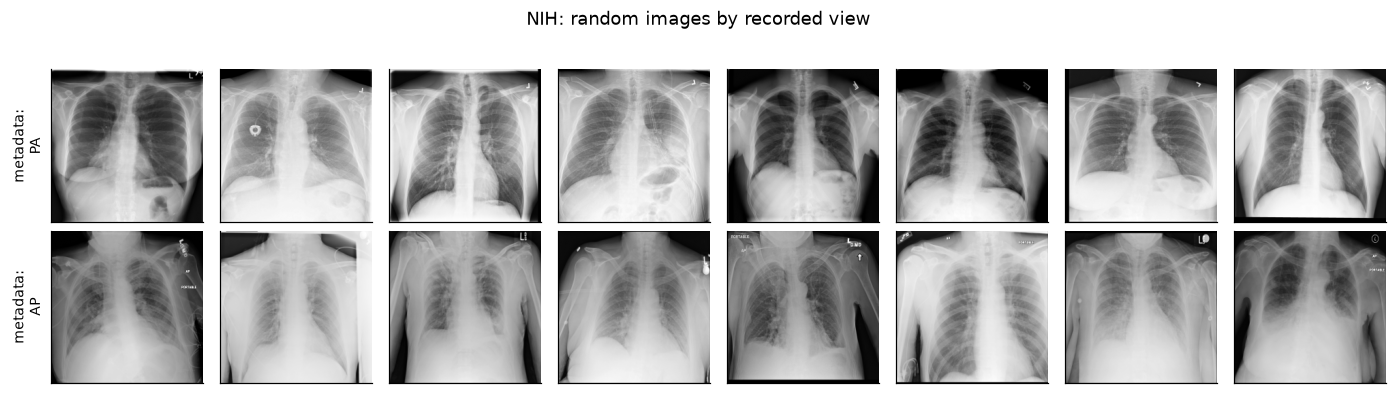

In [6]:
def view_grid(frame, name, views, n=8, seed=3):
    fig, axes = plt.subplots(len(views), n, figsize=(1.6 * n, 1.8 * len(views)))
    for r, v in enumerate(views):
        g = frame[frame["view"] == v].sample(n, random_state=seed)
        for c, path in enumerate(g["path"]):
            axes[r, c].imshow(cv2.imread(str(DATA_DIR / path), cv2.IMREAD_GRAYSCALE), cmap="gray")
            axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        axes[r, 0].set_ylabel(f"metadata:\n{v}", fontsize=9)
    fig.suptitle(f"{name}: random images by recorded view", y=1.0)
    plt.tight_layout()


# all NIH images, including the AP films excluded from the PA-only splits
nih_all = pd.DataFrame({"path": "nih_images/" + nih_raw["file"], "view": nih_raw["View Position"]})
view_grid(nih_all, "NIH", ["PA", "AP"])

PA rows are clean frontal films and AP rows show the "PORTABLE"/bedside markers expected of AP films, so the NIH `image_{k}` ↔ row *k* mapping looks correct. The anatomically sensible NIH PE+/PE− difference image in §9c supports this.

## 3. Pleural effusion prevalence

Prevalence is a design constant across experiments, so the class balance of each dataset
determines how large a fixed-prevalence training set can be.

In [7]:
prev = (df.groupby(["dataset", "split"], observed=True)["label"]
          .agg(n="size", positives="sum", prevalence="mean")
          .unstack("split"))
prev = prev.reindex(columns=["train", "test"], level=1)
prev

n         positives        prevalence       
split         train    test     train   test      train   test
dataset                                                       
NIH         62589.0  4721.0    6138.0  451.0      0.098  0.096
CheXpert     2388.0     NaN    1162.0    NaN      0.487    NaN
VinBigData  13000.0  2000.0     894.0  138.0      0.069  0.069

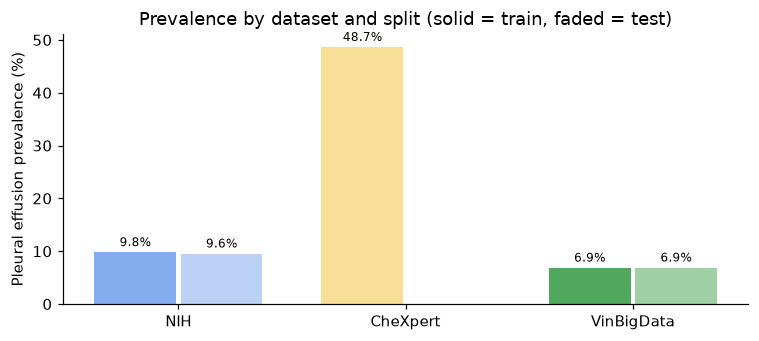

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
p = df.groupby(["dataset", "split"], observed=True)["label"].mean().unstack()[["train", "test"]]
x = np.arange(len(p))
for i, split in enumerate(["train", "test"]):
    bars = ax.bar(x + (i - 0.5) * 0.38, p[split] * 100, 0.36,
                  color=[COLORS[d] for d in p.index], alpha=1 if split == "train" else 0.55,
                  label=split)
    ax.bar_label(bars, fmt="%.1f%%", fontsize=8, padding=2)
ax.set_xticks(x, p.index)
ax.set_ylabel("Pleural effusion prevalence (%)")
ax.set_title("Prevalence by dataset and split (solid = train, faded = test)")
plt.tight_layout()

**VinBigData split check.** The split is drawn over unique `image_id`s (an earlier version sampled
annotation *rows*, which over-sampled abnormal images into the test set). Train and test should
have similar annotation density and prevalence:

In [9]:
rows_per_img = vb_rows.groupby("image_id").size().rename("annotation_rows")
tmp = vb.join(rows_per_img, on="image_id")
tmp.groupby("split")[["annotation_rows", "label"]].mean().rename(
    columns={"annotation_rows": "mean annotation rows / image", "label": "prevalence"})

,mean annotation rows / image,prevalence
split,,
test,4.412,0.069
train,4.545,0.069


## 5. Label quality

### 5a. VinBigData reader agreement
Each VinBigData training image was read by 3 radiologists. The current label is positive if
**any** reader marked pleural effusion; a majority (≥2/3) rule is a common alternative.

prevalence, any reader : 6.880%
prevalence, majority   : 4.227%
prevalence, unanimous  : 2.927%
of images with ≥1 positive read, 38.6% are single-reader positives


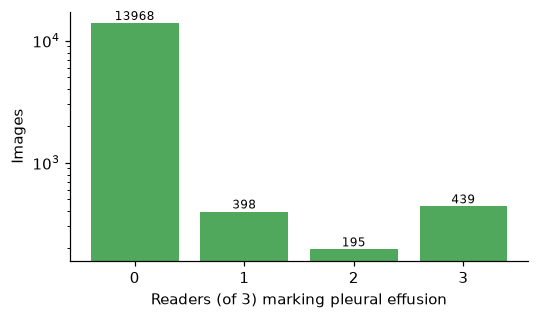

In [10]:
votes = vb.set_index("image_id")["pe_votes"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(votes.index.astype(str), votes.values, color=COLORS["VinBigData"])
ax.bar_label(bars, fontsize=8)
ax.set_yscale("log")
ax.set_xlabel("Readers (of 3) marking pleural effusion")
ax.set_ylabel("Images")
plt.tight_layout()

print(f"prevalence, any reader : {(vb['pe_votes'] >= 1).mean():.3%}")
print(f"prevalence, majority   : {(vb['pe_votes'] >= 2).mean():.3%}")
print(f"prevalence, unanimous  : {(vb['pe_votes'] == 3).mean():.3%}")
pos = vb[vb["pe_votes"] >= 1]
print(f"of images with ≥1 positive read, {(pos['pe_votes'] == 1).mean():.1%} are single-reader positives")

### 5b. CheXpert labelling
CheXbert outputs 1 (positive), 0 (negative), −1 (uncertain) or blank (not mentioned) for each report.
The label uses the **full-report** output only: 1 → positive, 0 or blank → negative, and −1 images
are dropped from the TRAIN/TEST CSVs (they stay on disk, which is why §2 shows CheXpert files
without a label).

In [11]:
raw = chx_report["Pleural Effusion"].map({1.0: "positive", 0.0: "negative", -1.0: "uncertain"}).fillna("not mentioned")
final = chx.set_index("image_id")["label"].map({True: "positive", False: "negative"})
final = final.reindex(chx_report.index).fillna("dropped").rename("final label")
pd.crosstab(raw, final, margins=True)

final label,dropped,negative,positive,All
Pleural Effusion,,,,
negative,1291,417,0,1708
not mentioned,2702,809,0,3511
positive,3771,0,1162,4933
uncertain,219,0,0,219
All,7983,1226,1162,10371


## 6. Demographics and view position

Demographics are available for NIH and CheXpert from the downloaded metadata (VinBigData PNGs were
stripped of DICOM tags).

11 implausible ages (<0 or >100) set to NaN


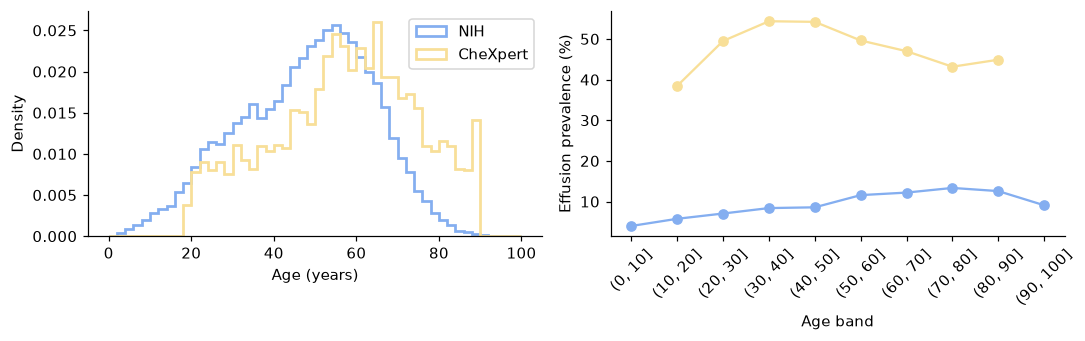

In [12]:
demo = df[df["dataset"].isin(["NIH", "CheXpert"])].copy()
n_bad_age = ((demo["age"] > 100) | (demo["age"] < 0)).sum()
print(f"{n_bad_age} implausible ages (<0 or >100) set to NaN")
demo.loc[(demo["age"] > 100) | (demo["age"] < 0), "age"] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for name, g in demo.groupby("dataset", observed=True):
    axes[0].hist(g["age"].dropna(), bins=np.arange(0, 101, 2), density=True, histtype="step",
                 lw=1.8, color=COLORS[name], label=name)
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Density")
axes[0].legend()

for name, g in demo.groupby("dataset", observed=True):
    by_age = g.groupby(pd.cut(g["age"], np.arange(0, 101, 10)), observed=True)["label"].mean() * 100
    axes[1].plot(by_age.index.astype(str), by_age.values, "o-", color=COLORS[name], label=name)
axes[1].set_xlabel("Age band")
axes[1].set_ylabel("Effusion prevalence (%)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()

In [13]:
sex = demo.groupby(["dataset", "sex"], observed=True)["label"].agg(n="size", prevalence="mean")
sex["share"] = sex["n"] / sex.groupby("dataset", observed=True)["n"].transform("sum")
sex

n  prevalence  share
dataset  sex                          
NIH      F    30167       0.099  0.448
         M    37143       0.097  0.552
CheXpert F      845       0.472  0.355
         M     1534       0.495  0.645

## 8. Co-occurring findings

Which other labels appear alongside pleural effusion? Strong co-occurrence (e.g. with
cardiomegaly or support devices) is a potential shortcut and differs across label taxonomies.

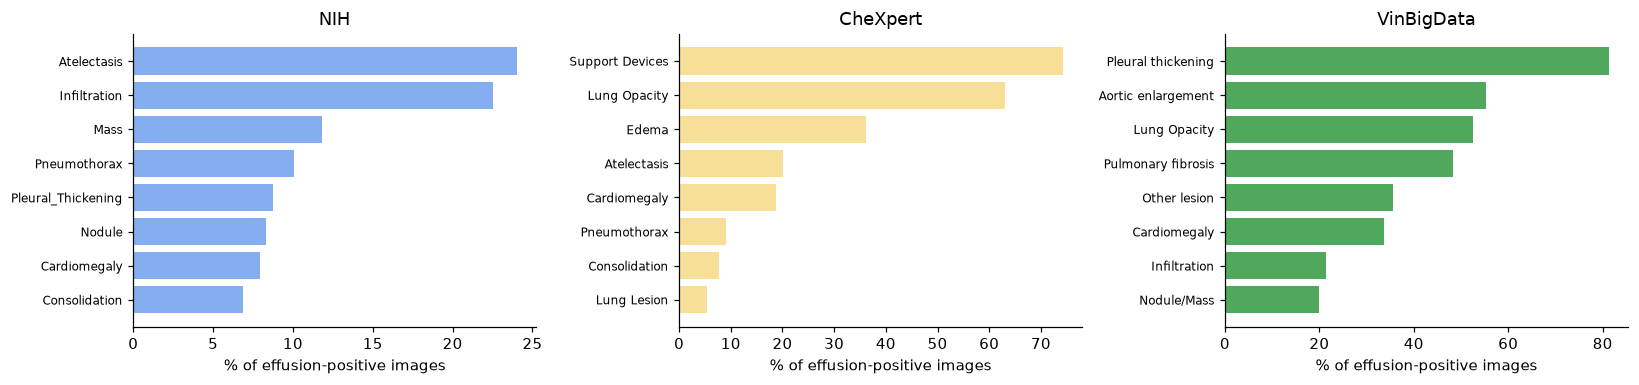

In [15]:
def top_cooccurring(g, k=8):
    pe_imgs = g.loc[g["label"], "findings"].explode()
    pe_imgs = pe_imgs[~pe_imgs.str.contains("effusion", case=False, na=True)]
    return (pe_imgs.value_counts() / g["label"].sum()).head(k)


fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, name in zip(axes, DATASETS):
    top = top_cooccurring(df[df["dataset"] == name])[::-1]
    ax.barh(top.index, top.values * 100, color=COLORS[name])
    ax.set_title(name)
    ax.set_xlabel("% of effusion-positive images")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()

In [16]:
def n_other(f):
    if not isinstance(f, list):
        return np.nan
    return len([x for x in f if x.lower() not in ("normal", "no finding") and "effusion" not in x.lower()])


n_findings = df.assign(n=df["findings"].apply(n_other))
n_findings.groupby(["dataset", "label"], observed=True)["n"].mean().unstack().rename(
    columns={False: "PE− images", True: "PE+ images"}).rename_axis(columns="mean # other findings")

mean # other findings,PE− images,PE+ images
dataset,,
NIH,0.469,1.099
CheXpert,1.914,2.456
VinBigData,0.731,4.000


## 9. Pixel-level comparison

A random sample of images per dataset is loaded to compare appearance — the most direct view of
the domain shift the model has to cross.

In [17]:
N_PER_DATASET = 600


def load(path):
    return cv2.imread(str(DATA_DIR / path), cv2.IMREAD_UNCHANGED)


sample = df.groupby("dataset", observed=True).sample(N_PER_DATASET, random_state=0).reset_index(drop=True)
imgs = [load(p) for p in sample["path"]]
sample["shape"] = [None if im is None else im.shape for im in imgs]
sample["dtype"] = [None if im is None else str(im.dtype) for im in imgs]
sample.groupby(["dataset", "shape", "dtype"], observed=True).size().rename("n").to_frame()

,,,n
dataset,shape,dtype,
NIH,"(224, 224)",uint8,600
CheXpert,"(224, 224)",uint8,600
VinBigData,"(224, 224)",uint8,600


In [18]:
ok = [im is not None and im.shape == (224, 224) for im in imgs]
sample = sample[ok].reset_index(drop=True)
X = np.stack([im for im, keep in zip(imgs, ok) if keep]).astype(np.float32) / 255.0
print(X.shape)

(1800, 224, 224)


### 9a. Example images (top row: effusion-positive, bottom row: negative)

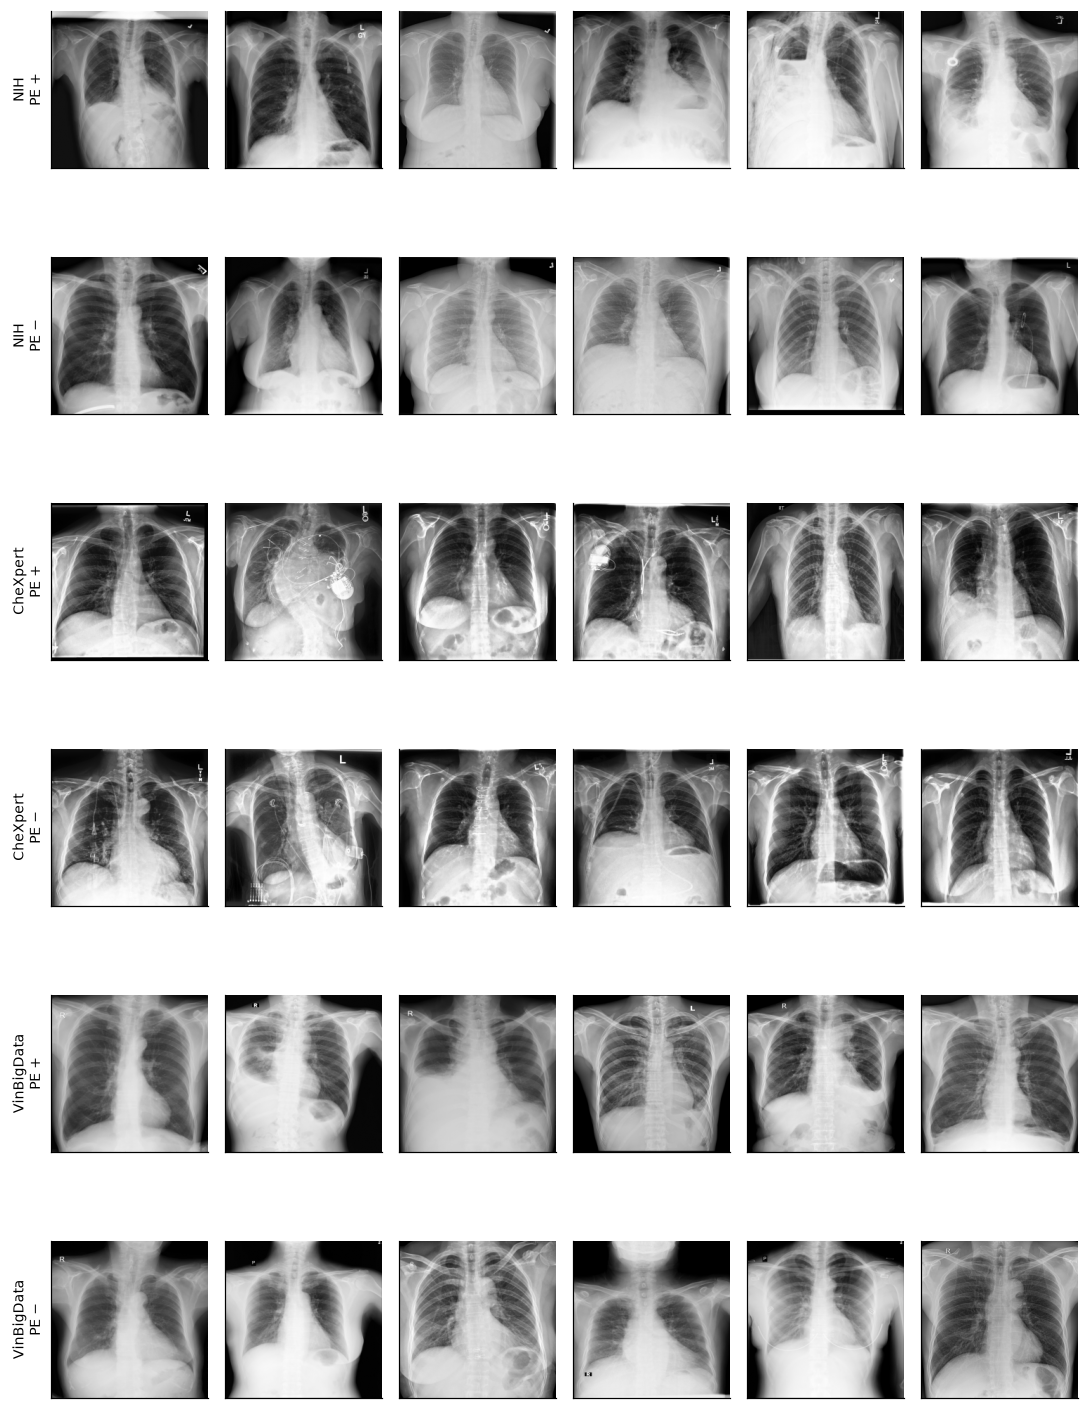

In [19]:
fig, axes = plt.subplots(2 * len(DATASETS), 6, figsize=(10, 14))
for r, name in enumerate(DATASETS):
    for c_lab, lab in enumerate([True, False]):
        g = df[(df["dataset"] == name) & (df["label"] == lab)].sample(6, random_state=1)
        for c, path in enumerate(g["path"]):
            ax = axes[2 * r + c_lab, c]
            ax.imshow(load(path), cmap="gray")
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(f"{name}\n{'PE +' if lab else 'PE −'}", fontsize=9)
plt.tight_layout()

### 9b. Intensity statistics

,mean_px,std_px,frac_black,frac_white
dataset,,,,
NIH,0.509,0.240,0.047,2.605e-04
CheXpert,0.508,0.290,0.024,1.784e-02
VinBigData,0.552,0.251,0.062,2.330e-03


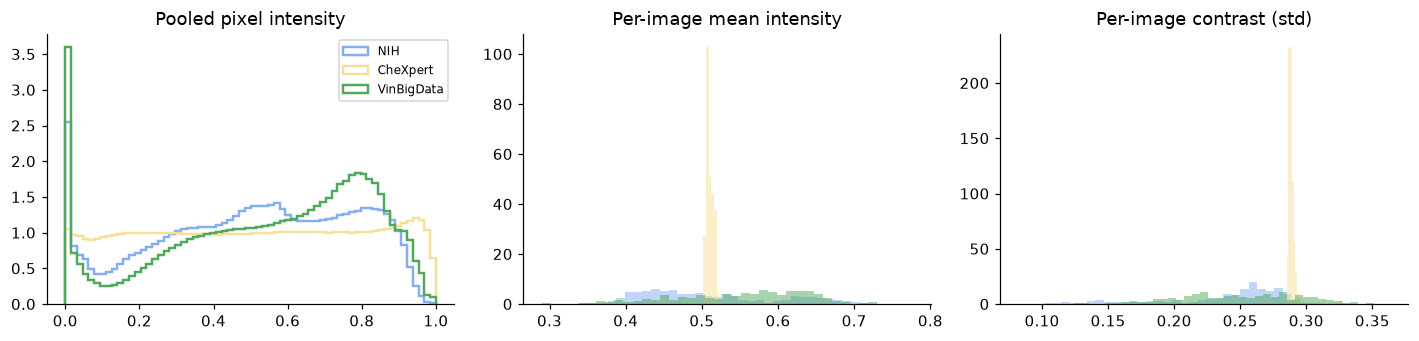

In [20]:
sample["mean_px"] = X.mean(axis=(1, 2))
sample["std_px"] = X.std(axis=(1, 2))
sample["frac_black"] = (X < 0.02).mean(axis=(1, 2))
sample["frac_white"] = (X > 0.98).mean(axis=(1, 2))
display(sample.groupby("dataset", observed=True)[["mean_px", "std_px", "frac_black", "frac_white"]].mean())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for name in DATASETS:
    m = (sample["dataset"] == name).values
    axes[0].hist(X[m].ravel(), bins=64, density=True, histtype="step", lw=1.6, color=COLORS[name], label=name)
    axes[1].hist(sample.loc[m, "mean_px"], bins=40, density=True, alpha=0.5, color=COLORS[name])
    axes[2].hist(sample.loc[m, "std_px"], bins=40, density=True, alpha=0.5, color=COLORS[name])
axes[0].set_title("Pooled pixel intensity"); axes[0].legend(fontsize=8)
axes[1].set_title("Per-image mean intensity")
axes[2].set_title("Per-image contrast (std)")
plt.tight_layout()

### 9c. Mean images
Average image per dataset, and the difference between the mean effusion-positive and
effusion-negative image. Systematic differences in framing, collimation, text markers or
positioning show up here.

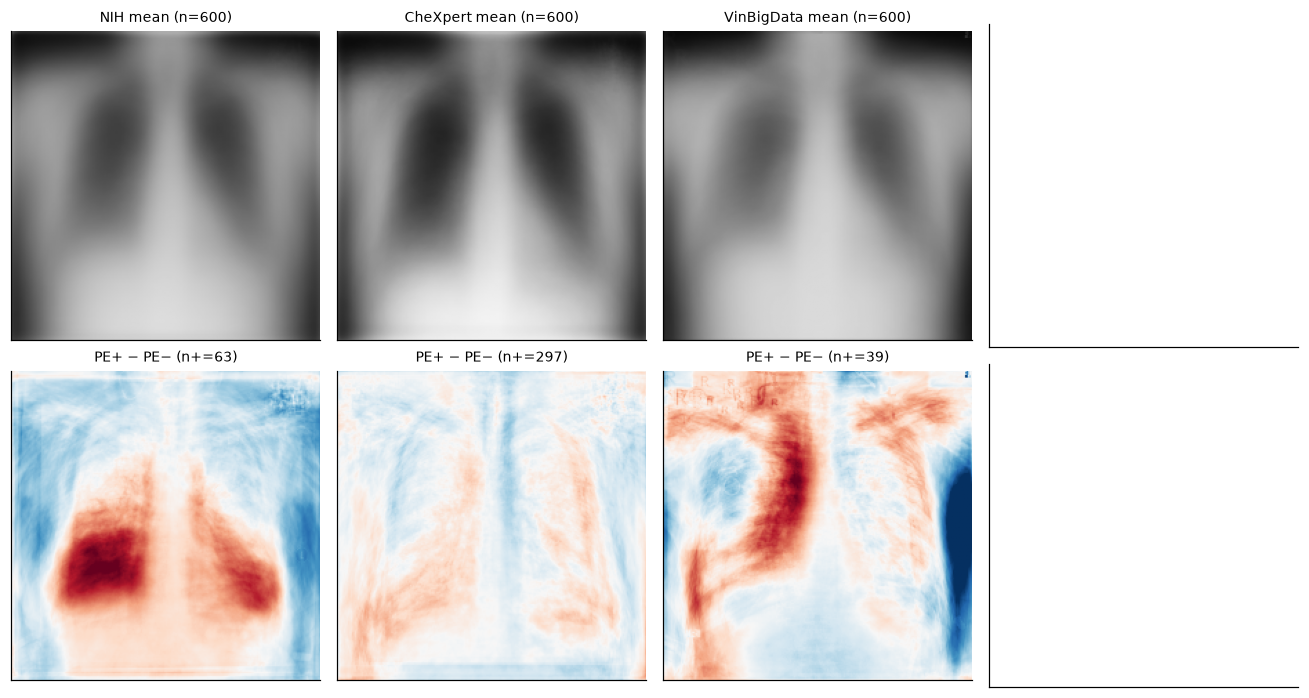

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for c, name in enumerate(DATASETS):
    m = (sample["dataset"] == name).values
    axes[0, c].imshow(X[m].mean(0), cmap="gray", vmin=0, vmax=1)
    axes[0, c].set_title(f"{name} mean (n={m.sum()})", fontsize=9)
    pos_m = m & sample["label"].values
    neg_m = m & ~sample["label"].values
    if pos_m.sum() >= 5:
        diff = X[pos_m].mean(0) - X[neg_m].mean(0)
        axes[1, c].imshow(diff, cmap="RdBu_r", vmin=-0.15, vmax=0.15)
    axes[1, c].set_title(f"PE+ − PE− (n+={pos_m.sum()})", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

### 9d. How separable are the domains?
PCA on 32×32 thumbnails. If datasets form distinct clusters even in raw pixel space, a CNN can
trivially identify the source site — which matters when site and prevalence are correlated.

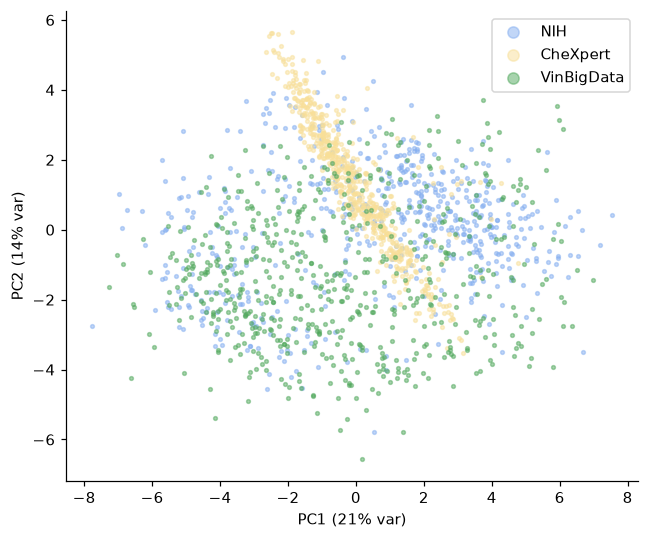

In [22]:
thumbs = np.stack([cv2.resize(x, (32, 32), interpolation=cv2.INTER_AREA) for x in X]).reshape(len(X), -1)
Z = thumbs - thumbs.mean(0)
U, S, Vt = np.linalg.svd(Z, full_matrices=False)
pcs = Z @ Vt[:2].T
explained = S[:2] ** 2 / (S ** 2).sum()

fig, ax = plt.subplots(figsize=(6, 5))
for name in DATASETS:
    m = (sample["dataset"] == name).values
    ax.scatter(pcs[m, 0], pcs[m, 1], s=6, alpha=0.5, color=COLORS[name], label=name)
ax.set_xlabel(f"PC1 ({explained[0]:.0%} var)")
ax.set_ylabel(f"PC2 ({explained[1]:.0%} var)")
ax.legend(markerscale=3)
plt.tight_layout()

In [23]:
# Nearest-centroid site classifier on the top 20 PCs (5-fold): a crude lower bound on how
# identifiable each site is from pixels alone. Chance = 33%.
k = 20
feats = Z @ Vt[:k].T
y = sample["dataset"].astype(str).values
folds = RNG.permutation(len(y)) % 5
pred = np.empty_like(y)
for f in range(5):
    tr, te = folds != f, folds == f
    cents = {d: feats[tr & (y == d)].mean(0) for d in DATASETS}
    dists = np.stack([np.linalg.norm(feats[te] - cents[d], axis=1) for d in DATASETS], axis=1)
    pred[te] = np.array(DATASETS)[dists.argmin(1)]
print(f"site-identification accuracy: {(pred == y).mean():.1%}")
pd.crosstab(pd.Series(y, name="true"), pd.Series(pred, name="predicted"))

site-identification accuracy: 63.4%


predicted,CheXpert,NIH,VinBigData
true,,,
CheXpert,442,144,14
NIH,146,290,164
VinBigData,40,150,410


## 10. Summary table

In [24]:
summary = pd.DataFrame({
    "images": df.groupby("dataset", observed=True).size(),
    "patients": df.groupby("dataset", observed=True)["patient_id"].nunique(),
    "train_images": df[df["split"] == "train"].groupby("dataset", observed=True).size(),
    "test_images": df[df["split"] == "test"].groupby("dataset", observed=True).size(),
    "train_prevalence": df[df["split"] == "train"].groupby("dataset", observed=True)["label"].mean(),
    "train_positives": df[df["split"] == "train"].groupby("dataset", observed=True)["label"].sum(),
    "AP_share": df.groupby("dataset", observed=True)["view"].apply(lambda v: v.eq("AP").mean()),
    "median_age": df.groupby("dataset", observed=True)["age"].median(),
    "female_share": df.groupby("dataset", observed=True)["sex"].apply(
        lambda s: s.eq("F").sum() / s.notna().sum() if s.notna().any() else np.nan),
})
summary

,images,patients,train_images,test_images,train_prevalence,train_positives,AP_share,median_age,female_share
dataset,,,,,,,,,
NIH,67310,28868,62589,4721.0,0.098,6138,0.0,49.0,0.448
CheXpert,2388,2388,2388,NaN,0.487,1162,0.0,58.0,0.355
VinBigData,15000,15000,13000,2000.0,0.069,894,0.0,NaN,NaN


## Notes for the modelling stage

Points raised by this EDA that are worth deciding on before training (see the tables above
for the numbers):

- **Prevalence differs a lot across sources** — roughly 48% CheXpert, 10% NIH (PA only), 7% VinBigData. Fixing training prevalence means resampling, and the dataset with the fewest
  positives (CheXpert: negatives) at the chosen prevalence caps the training-set size for every
  experiment (§3). Target-only training at VinBigData prevalence is capped by VinBigData's
  13,000 training images (2,000 are held out for testing), and CheXpert can only contribute
  ~1.3k images at that prevalence.
- **VinBigData reader disagreement.** Labels use the "any reader" rule; a "majority" rule is the
  main alternative, and a sizeable share of positives are
  single-reader calls (§5a).
- **CheXpert labels come from the full report only**; the 219 uncertain (−1) images are excluded (§5b).
- **Projection:** all three datasets are PA only (§6). For CheXpert this leaves 2,388 of the 10,152
  downloaded images, all used for training (no CheXpert test split), so CheXpert is now very small.
- **Aspect-ratio distortion** from the direct 224×224 resize differs by source (§7).
- **Sites are distinguishable from raw pixels** (§9d), so any correlation between site and label
  in mixed training sets is a potential shortcut.